# CCEP pilot: dependence character before stimulation

Five participants from [ds004080](https://openneuro.org/datasets/ds004080/versions/1.2.4). Ask which dependence-character contrasts are reproducible across baseline windows, interpretable through original edges, and compatible with measured evoked-response properties. Participants are the independent units; windows are repeated measurements. [Protocol](../notes/ccep-pilot-261014.md).

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'pyproject.toml').is_file() and (p/'research/empirical/ccep_pilot').is_dir())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from research.empirical.ccep_pilot.plots import scope_figures, contact_qc_figure
RUN=ROOT/'results/ccep-pilot-261014'
participants=json.loads((RUN/'scope/participants.json').read_text())
quality=pd.read_csv(RUN/'scope/quality.csv')
sampling=pd.read_csv(RUN/'scope/sampling.csv')
scope_figures(RUN)
contact_qc_figure(RUN)
def show(name): display(Image(filename=str(RUN/'figures'/f'{name}.png')))
display(pd.DataFrame([dict(participant=r['subject'][-2:], M=r['M'], native_Hz=r['native_fs'], before_first_pulse_s=round(r['first_pulse'],1), candidate_32s_windows=len(r['starts']), candidate_64s_windows=len(r['available_windows']['64'])) for r in participants]))

,participant,M,native_Hz,before_first_pulse_s,candidate_32s_windows,candidate_64s_windows
0,02,86,2048,255.7,3,0
1,10,88,2048,532.6,3,3
2,12,107,2048,560.9,3,2
3,61,64,2048,355.6,3,3
4,73,48,2048,232.3,3,0


## Scope and sampling

All 49 source files passed pinned SHA256/size checks. Retain only declared-good surface ECoG contacts; exclude depth/auxiliary contacts, annotated artefacts with filter margins, and five minutes around the seizure annotated in participant 10. Numerical checks found no additional flat/nonfinite contacts. Full-duration inspection and native verification nevertheless found an isolated slow C26 excursion in participant 73, first window; its origin is unresolved. Exclude this interval before viewing p90 results, retain the contact, and match its reference control to the first remaining window. Acquisition reference is G2, described as “probably mastoid”; the pilot uses an explicit common average and one matched acquisition-reference control per participant.

The working choice is **32 contiguous seconds, 128 Hz, T=4096, 0.5–45 Hz**, with three disjoint windows per participant except 73, which retains two. There are 19 primary/control tables across five independent participants. Thirteen diagnostic edge profiles and 78 cross-profile features compare physical lags and fixed frequency bands against native-rate data. This supports low-frequency analysis, not preservation of all neural information or invariance of the entire p90 catalogue. Native 2048 Hz files are retained for responses.

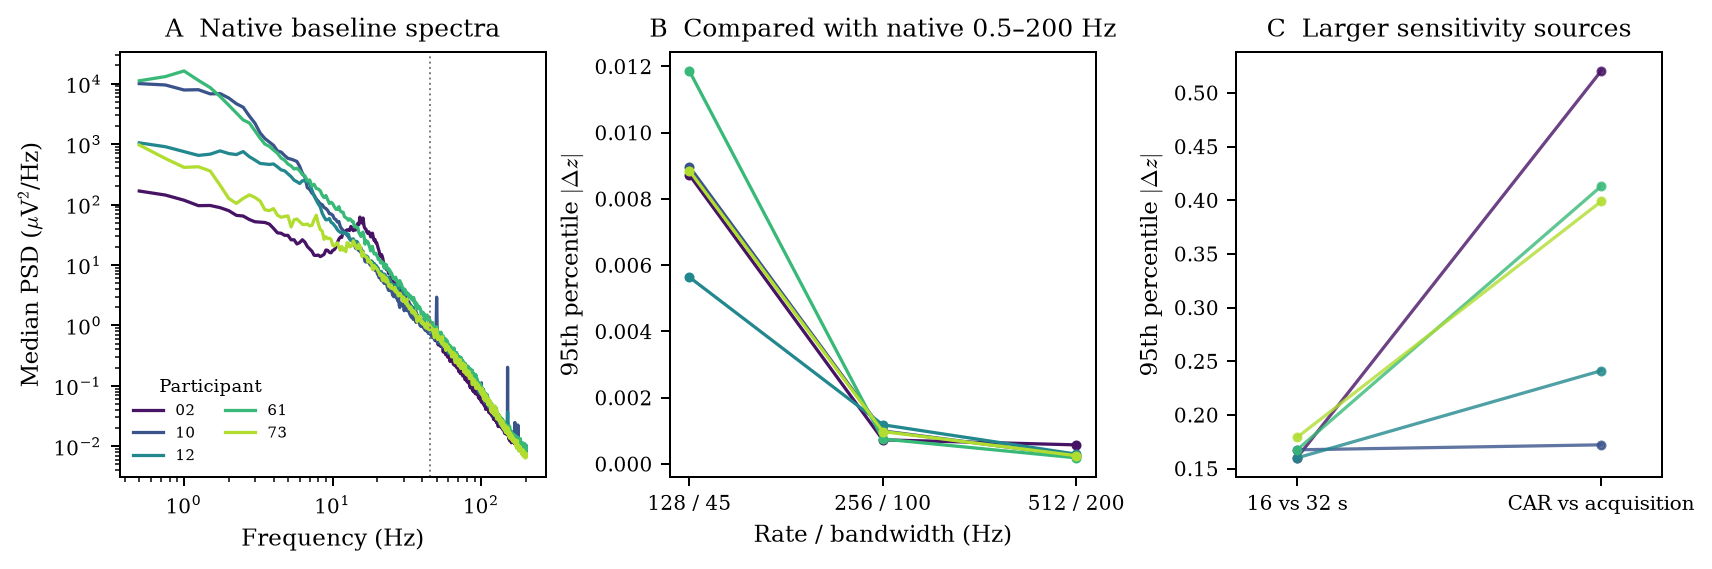

In [2]:
show('sampling-overview')

Panel A shows median-across-contact native spectra in the first retained window. B shows the largest window-wise 95th-percentile feature difference from the native 0.5–200 Hz reference. C contrasts median 16-versus-32-s differences with first-window reference sensitivity, at 128 Hz. Different windows can differ physiologically; these checks do not isolate estimation noise. These initial diagnostic panels cover the 15 candidate windows; the subsequently excluded interval remains visible as QC evidence. Primary analyses use the 14 retained windows.

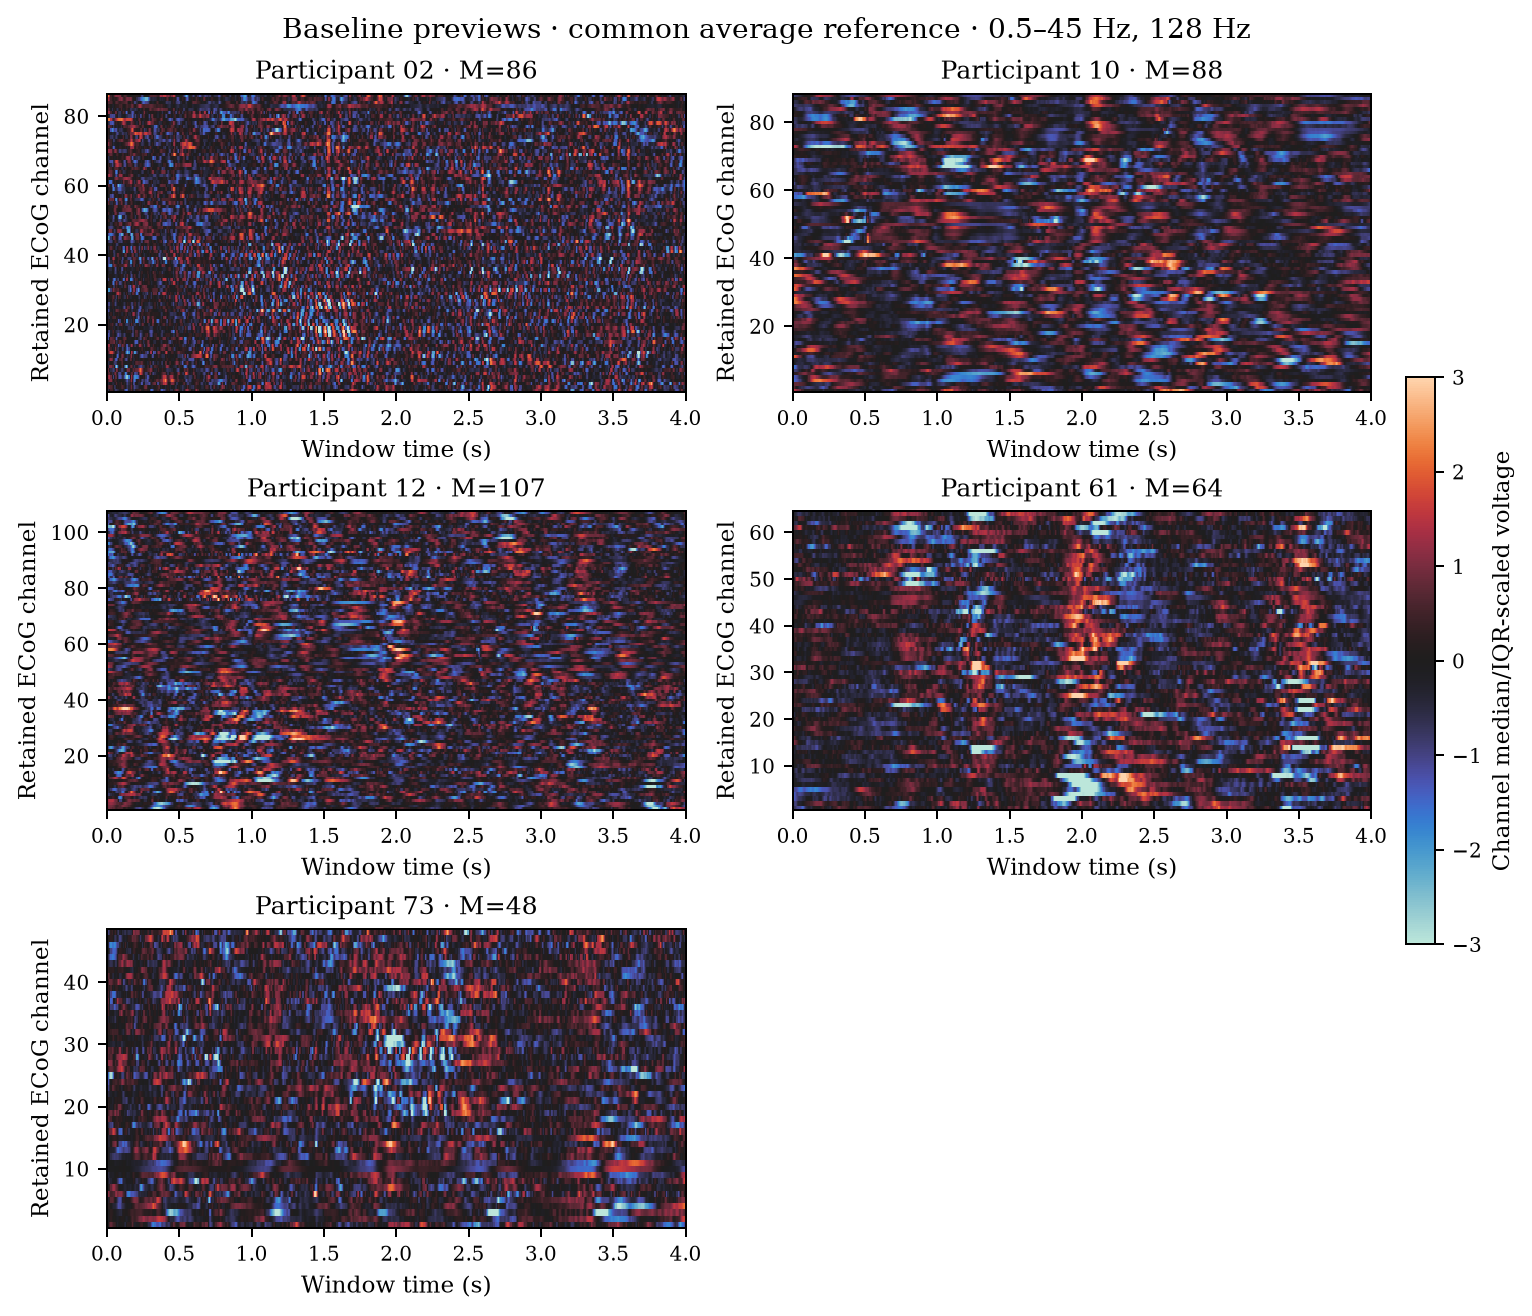

,edge_rmse_max,z_error_p95
fs,,
128,0.0123,0.0119
256,0.0007,0.0012
512,0.0003,0.0006


In [3]:
show('baseline-heatmaps')
display(sampling.query("comparison == 'bandwidth_vs_200Hz'").groupby('fs')[['edge_rmse_max','z_error_p95']].max().round(4))

## Duration and reference are material

64-second comparisons are possible in three participants; two lack suitable annotated-clean intervals of that length. Thirty-two seconds improves agreement relative to 16 seconds, but does not establish a perfectly stable recording-level signature. Keep repeated windows and require an interpreted contrast to exceed its temporal/reference sensitivity.

In [4]:
long=pd.read_csv(RUN/'scope/long-duration.csv')
display(long.groupby(['subject','duration'])[['z_error_median','z_error_p95']].median().round(3))
display(pd.read_csv(RUN/'scope/reference.csv').query('fs == 128')[['subject','z_error_median','z_error_p95']].round(3))

z_error_median  z_error_p95
subject           duration                             
sub-ccepAgeUMCU10 16                 0.170        0.291
                  32                 0.075        0.132
sub-ccepAgeUMCU12 16                 0.206        0.301
                  32                 0.096        0.163
sub-ccepAgeUMCU61 16                 0.118        0.294
                  32                 0.054        0.125

,subject,z_error_median,z_error_p95
0,sub-ccepAgeUMCU02,0.209,0.520
3,sub-ccepAgeUMCU10,0.039,0.172
6,sub-ccepAgeUMCU12,0.096,0.241
9,sub-ccepAgeUMCU61,0.154,0.413
12,sub-ccepAgeUMCU73,0.108,0.399


## Full-p90 analysis

Frozen pyspi `fd0de71`, computation r9, full edges. At 14 October 10:13 UTC, 18/19 pilot tables validate with 96.77–96.87% finite edges. The final reference control exceeded its three-hour limit; its next attempt retains eight workers/48 GiB, allows six hours and enables per-SPI checkpoints. Analysis is already queued behind it and will validate all 19 before fitting first-window PCA and projecting repeated windows/reference controls. No PC1 or baseline–response finding is asserted. Failed parametric Granger variants remain NaN.

In [5]:
receipt=json.loads((RUN/'execution.json').read_text())
display(pd.DataFrame(receipt['jobs'].get('smokes',[]))[['participant','M','T','workers','id','status']])
summary_path=RUN/'analysis/summary.json'
if summary_path.exists():
    summary=json.loads(summary_path.read_text())
    print(summary.get('interpretation','Verified analysis available; inspect original-edge contrasts.'))
    for name in ('pca','loadings','edge-contrasts'):
        if (RUN/'figures'/f'{name}.png').exists(): show(name)
else:
    print('Full-p90 extraction is in progress. Loadings and participant-level interpretations require the retained-window and reference controls.')

,participant,M,T,workers,id,status
0,02,86,4096,4,181159856.gadi-pbs,complete; source and coverage validated
1,10,88,4096,4,181159862.gadi-pbs,complete; source and coverage validated
2,12,107,4096,4,181159868.gadi-pbs,complete; source and coverage validated
3,61,64,4096,1,181159873.gadi-pbs,running last checked
4,73,48,4096,3,181173419.gadi-pbs,"submitted; reviewed corpus, first retained window"


Full-p90 extraction is in progress. Loadings and participant-level interpretations require the retained-window and reference controls.


## Matched evoked responses

Published N1 samples match the exact selected runs and retained contacts. Exclude an entire stimulation site if its published average includes pulses near annotated artefacts or the seizure margin. Native 2048 Hz traces verify timing without imposing the baseline low-pass choice. Unequal stimulation coverage and intensity limit comparisons; these summaries establish feasibility, not an association with SPI–SPI.

,subject,eligible_sites,detected_responses,pooled_median_ms,median_within_site_iqr_ms
0,sub-ccepAgeUMCU02,2,17,19.04,3.30
1,sub-ccepAgeUMCU10,17,180,33.45,11.11
2,sub-ccepAgeUMCU12,44,402,26.86,10.38
3,sub-ccepAgeUMCU61,43,301,34.18,12.15
4,sub-ccepAgeUMCU73,13,64,18.80,10.50


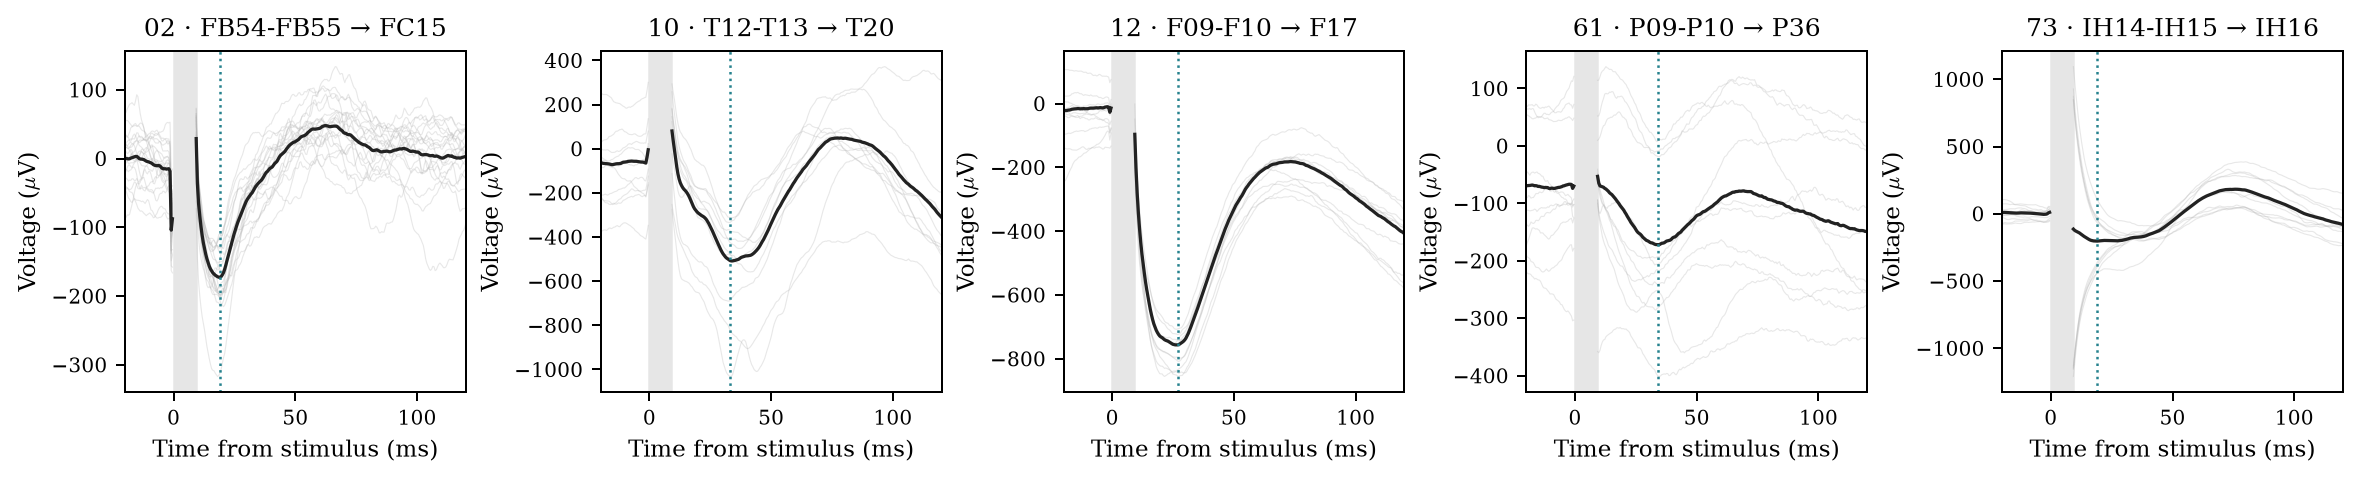

In [6]:
from research.empirical.ccep_pilot.plots import response_figures
response_figures(RUN)
display(pd.read_csv(RUN/'responses/summary.csv')[['subject','eligible_sites','detected_responses','pooled_median_ms','median_within_site_iqr_ms']].round(2))
show('native-response-examples')

Grey: individual trials; black: mean; dotted: published N1 latency. The first 9 ms are hidden because of the stimulation artefact. Median within-site IQR gives equal weight to eligible sites with at least five detected responses; dyads are not independent participants.